# Lekce 09 - Pandas

Obsah:

* proč pandas
* tabulka `DataFrame` a sloupec `Series`
* načtení tabulky ze souboru CSV
* výběr řádků a sloupců
* nové sloupce a řazení
* chybějící hodnoty
* seskupování: `groupby`
* čas v tabulce
* časté chyby

Na konec, mimo látku: výkaz výměr z BIM modelu.

## 1. Proč pandas

Tabulky jsou ve stavebnictví všude: rozpočet, výkaz výměr, harmonogram,
deník dodávek, data ze senzorů. Excel je na ně výborný, dokud se stejná úprava
nemusí dělat znovu a znovu, nebo dokud tabulka nemá statisíce řádků.

**Pandas** je tabulka v Pythonu. Každý sloupec tabulky je pole NumPy, takže
všechno z lekce 8 funguje i tady: výpočet bez cyklu, masky, agregace.
Instalace a obvyklý import:

```
uv add pandas
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 2. Tabulka `DataFrame` a sloupec `Series`

Tabulku vytvoříme ze slovníku seznamů. Klíč je název sloupce, seznam jsou
hodnoty ve sloupci:

In [2]:
betony = pd.DataFrame({
    "trida": ["C16/20", "C20/25", "C25/30", "C30/37"],
    "f_ck": [16, 20, 25, 30],          # MPa
    "cena": [2950, 3100, 3300, 3550],  # Kc za m3
})
betony

,trida,f_ck,cena
0,C16/20,16,2950
1,C20/25,20,3100
2,C25/30,25,3300
3,C30/37,30,3550


Čísla vlevo jsou **index**, popisky řádků. Pandas je doplnil sám: 0, 1, 2, ...

Jeden sloupec vybraný hranatými závorkami je **`Series`**: pole NumPy
s indexem a názvem. Počítá se s ním stejně jako s polem:

In [3]:
f_ck = betony["f_ck"]
print(type(f_ck))
print(f_ck / 1.5)
print("nejvyssi f_ck:", f_ck.max())

<class 'pandas.Series'>
0    10.666667
1    13.333333
2    16.666667
3    20.000000
Name: f_ck, dtype: float64
nejvyssi f_ck: 30


In [4]:
print(betony.shape)        # (radky, sloupce)
print(betony.columns)      # nazvy sloupcu

(4, 3)
Index(['trida', 'f_ck', 'cena'], dtype='str')


## 3. Načtení tabulky ze souboru CSV

Ručně se velké tabulky nepíšou. Obvykle přijdou jako soubor, nejčastěji
**CSV** (comma separated values): obyčejný text, jeden řádek tabulky na
řádek souboru, hodnoty oddělené čárkou, na prvním řádku názvy sloupců.
Začátek souboru `Data/rozpocet.csv`:

```
oddil,polozka,mj,mnozstvi,jedn_cena
Zemní práce,Sejmutí ornice,m3,48.0,95
Zemní práce,Hloubení rýh pro základy,m3,32.5,420
...
```

Práci se soubory probereme v lekci 10. Teď stačí jedna funkce. Cesta
k souboru se počítá od složky, ve které leží notebook:

In [5]:
rozpocet = pd.read_csv("Data/rozpocet.csv")
rozpocet.head()           # prvnich 5 radku

,oddil,polozka,mj,mnozstvi,jedn_cena
0,Zemní práce,Sejmutí ornice,m3,48.0,95.0
1,Zemní práce,Hloubení rýh pro základy,m3,32.5,420.0
2,Zemní práce,Odvoz zeminy,m3,60.0,310.0
3,Zemní práce,Zásyp a hutnění,m3,18.0,260.0
4,Základy,Podkladní beton C12/15,m3,6.2,3150.0


Na novou tabulku se vždycky nejdřív podívejte. Tři metody na první pohled:

* `info()` - sloupce, jejich typy a počet vyplněných hodnot
* `describe()` - základní statistika číselných sloupců
* `head(n)`, `tail(n)` - prvních a posledních `n` řádků

In [6]:
rozpocet.info()

<class 'pandas.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   oddil      28 non-null     str    
 1   polozka    28 non-null     str    
 2   mj         28 non-null     str    
 3   mnozstvi   28 non-null     float64
 4   jedn_cena  27 non-null     float64
dtypes: float64(2), str(3)
memory usage: 1.2 KB


In [7]:
rozpocet.describe()

,mnozstvi,jedn_cena
count,28.000000,27.000000
mean,94.467857,7177.037037
std,147.779107,11907.643332
min,1.000000,65.000000
25%,8.700000,480.000000
50%,28.650000,1240.000000
75%,124.000000,5045.000000
max,610.000000,42000.000000


Všimněte si, že `jedn_cena` má jen 27 vyplněných hodnot z 28. K tomu se vrátíme
v oddílu 6. Typ `str` znamená text, `float64` desetinná čísla, stejně jako
`dtype` v NumPy.

## 4. Výběr řádků a sloupců

**Sloupce.** Jeden sloupec jedněmi hranatými závorkami, víc sloupců
seznamem, tedy **dvojími** závorkami:

In [8]:
rozpocet[["polozka", "mnozstvi", "mj"]].head(3)

,polozka,mnozstvi,mj
0,Sejmutí ornice,48.0,m3
1,Hloubení rýh pro základy,32.5,m3
2,Odvoz zeminy,60.0,m3


**Řádky.** Řádky se vybírají dvěma způsoby:

* `loc[radky, sloupce]` - podle **popisku** indexu a názvu sloupce;
  pozor, výřez `loc[4:7]` **obsahuje** i řádek 7
* `iloc[radky, sloupce]` - podle **pořadí**, jako indexování pole; konec
  výřezu se nezahrnuje

In [9]:
rozpocet.loc[4:7, ["polozka", "mnozstvi", "jedn_cena"]]

,polozka,mnozstvi,jedn_cena
4,Podkladní beton C12/15,6.2,3150.0
5,Základové pasy C20/25,24.8,3480.0
6,Základová deska C25/30,18.6,3720.0
7,Výztuž základové desky B500B,1.1,32500.0


In [10]:
print(rozpocet.iloc[0, 1])        # prvni radek, druhy sloupec
print(rozpocet.loc[0, "polozka"])  # totez podle nazvu

Sejmutí ornice
Sejmutí ornice


**Filtrování maskou** funguje jako v NumPy. Porovnání sloupce dá masku
`True`/`False` a tabulka s maskou v závorkách vrátí jen řádky, kde maska
platí:

In [11]:
betonove = rozpocet["mj"] == "m3"
rozpocet[betonove]

,oddil,polozka,mj,mnozstvi,jedn_cena
0,Zemní práce,Sejmutí ornice,m3,48.0,95.0
1,Zemní práce,Hloubení rýh pro základy,m3,32.5,420.0
2,Zemní práce,Odvoz zeminy,m3,60.0,310.0
3,Zemní práce,Zásyp a hutnění,m3,18.0,260.0
4,Základy,Podkladní beton C12/15,m3,6.2,3150.0
5,Základy,Základové pasy C20/25,m3,24.8,3480.0
6,Základy,Základová deska C25/30,m3,18.6,3720.0
12,Vodorovné konstrukce,Stropní deska C25/30,m3,21.4,3890.0
15,Vodorovné konstrukce,Železobetonové schodiště,m3,2.1,6200.0
16,Střecha,Dřevěný krov,m3,7.8,14500.0


In [12]:
velke = (rozpocet["mj"] == "m2") & (rozpocet["mnozstvi"] > 150)
rozpocet[velke]

,oddil,polozka,mj,mnozstvi,jedn_cena
8,Svislé konstrukce,Obvodové zdivo 440 mm,m2,185.0,1890.0
18,Střecha,Betonová střešní krytina,m2,156.0,820.0
24,Úpravy povrchů,Vnitřní omítky,m2,520.0,380.0
25,Úpravy povrchů,Vnější omítka,m2,195.0,640.0
26,Úpravy povrchů,Kontaktní zateplení EPS,m2,195.0,1350.0
27,Úpravy povrchů,Malby,m2,610.0,65.0


Na textové sloupce se hodí ještě dvě metody: `isin` (je hodnota v seznamu?)
a `str.contains` (obsahuje text?):

In [13]:
konstrukce = rozpocet["oddil"].isin(["Základy", "Vodorovné konstrukce"])
print(rozpocet.loc[konstrukce, "polozka"])

print(rozpocet.loc[rozpocet["polozka"].str.contains("Výztuž"), "polozka"])

4           Podkladní beton C12/15
5            Základové pasy C20/25
6           Základová deska C25/30
7     Výztuž základové desky B500B
12            Stropní deska C25/30
13      Výztuž stropní desky B500B
14           Bednění stropní desky
15        Železobetonové schodiště
Name: polozka, dtype: str
7     Výztuž základové desky B500B
13      Výztuž stropní desky B500B
Name: polozka, dtype: str


Jaké hodnoty se ve sloupci vyskytují a kolikrát? K tomu slouží `unique()`
a `value_counts()`:

In [14]:
print(rozpocet["oddil"].unique())
print(rozpocet["mj"].value_counts())

<StringArray>
[         'Zemní práce',              'Základy',    'Svislé konstrukce',
 'Vodorovné konstrukce',              'Střecha',        'Výplně otvorů',
       'Úpravy povrchů']
Length: 7, dtype: str
mj
m3    10
m2    10
ks     5
t      2
m      1
Name: count, dtype: int64


## 5. Nové sloupce a řazení

Nový sloupec vznikne přiřazením. Výpočet běží na celých sloupcích, jako
v NumPy:

In [15]:
rozpocet["cena"] = rozpocet["mnozstvi"] * rozpocet["jedn_cena"]

celkem = rozpocet["cena"].sum()
print(f"celkem bez DPH: {celkem:,.0f} Kc")
print(f"celkem s DPH 21 %: {celkem * 1.21:,.0f} Kc")

celkem bez DPH: 2,353,822 Kc
celkem s DPH 21 %: 2,848,125 Kc


Formát `:,.0f` vypíše číslo s oddělovačem tisíců a bez desetinných míst.

**Řazení.** `sort_values` vrátí **novou** seřazenou tabulku. Původní
tabulka se nemění. Pět nejdražších položek:

In [16]:
rozpocet.sort_values("cena", ascending=False).head(5)

,oddil,polozka,mj,mnozstvi,jedn_cena,cena
8,Svislé konstrukce,Obvodové zdivo 440 mm,m2,185.0,1890.0,349650.0
26,Úpravy povrchů,Kontaktní zateplení EPS,m2,195.0,1350.0,263250.0
20,Výplně otvorů,Plastová okna,ks,12.0,18500.0,222000.0
24,Úpravy povrchů,Vnitřní omítky,m2,520.0,380.0,197600.0
18,Střecha,Betonová střešní krytina,m2,156.0,820.0,127920.0


**Změna hodnot maskou.** Co kdyby výztuž zdražila o 10 %? Úpravy zkusíme na
kopii, aby původní rozpočet zůstal. Hodnoty se mění přes `loc[maska, sloupec]`:

In [17]:
varianta = rozpocet.copy()
vyztuz = varianta["mj"] == "t"

varianta.loc[vyztuz, "jedn_cena"] = varianta.loc[vyztuz, "jedn_cena"] * 1.10
varianta["cena"] = varianta["mnozstvi"] * varianta["jedn_cena"]

print(f"puvodni: {rozpocet['cena'].sum():,.0f} Kc")
print(f"varianta: {varianta['cena'].sum():,.0f} Kc")

puvodni: 2,353,822 Kc
varianta: 2,366,185 Kc


## 6. Chybějící hodnoty

Prázdné políčko v CSV načte pandas jako `NaN` (not a number). Které položky
nemají cenu?

In [18]:
bez_ceny = rozpocet["jedn_cena"].isna()
rozpocet[bez_ceny]

,oddil,polozka,mj,mnozstvi,jedn_cena,cena
22,Výplně otvorů,Vnitřní dveře,ks,9.0,NaN,NaN


**Pozor:** `sum()` hodnoty `NaN` potichu přeskočí. Součet rozpočtu v oddílu 5
tedy vnitřní dveře vůbec neobsahoval a nikdo nás neupozornil. U každé nové
tabulky proto zkontrolujte, kolik hodnot chybí:

In [19]:
rozpocet.isna().sum()

oddil        0
polozka      0
mj           0
mnozstvi     0
jedn_cena    1
cena         1
dtype: int64

Co s chybějícími hodnotami udělat, je inženýrské rozhodnutí, ne
programátorské. Možnosti:

| Zápis | Co udělá |
|---|---|
| `df.loc[maska, "sloupec"] = hodnota` | doplní známou hodnotu |
| `df["sloupec"].fillna(hodnota)` | nahradí všechny `NaN` jednou hodnotou |
| `df.dropna()` | vyhodí řádky, kde něco chybí |

Cenu dveří zjistíme od dodavatele a doplníme:

In [20]:
rozpocet.loc[bez_ceny, "jedn_cena"] = 6800
rozpocet["cena"] = rozpocet["mnozstvi"] * rozpocet["jedn_cena"]
rozpocet["podil"] = rozpocet["cena"] / rozpocet["cena"].sum() * 100

print(f"celkem bez DPH: {rozpocet['cena'].sum():,.0f} Kc")
print("chybi:", rozpocet["cena"].isna().sum())

celkem bez DPH: 2,415,022 Kc
chybi: 0


## 7. Seskupování: `groupby`

Kolik stojí jednotlivé oddíly rozpočtu? Ručně bychom řádky rozdělili podle
oddílu, v každé skupině sečetli cenu a výsledky dali dohromady. Přesně to
dělá `groupby`:

In [21]:
po_oddilech = rozpocet.groupby("oddil")["cena"].sum()
po_oddilech.sort_values(ascending=False)

oddil
Úpravy povrchů          625300.0
Svislé konstrukce       540490.0
Výplně otvorů           389700.0
Střecha                 373560.0
Vodorovné konstrukce    233706.0
Základy                 210776.0
Zemní práce              41490.0
Name: cena, dtype: float64

Zápis se čte zleva: **rozděl** podle `oddil`, vezmi sloupec `cena`,
v každé skupině **sečti**. Místo `sum` může být jakákoli agregace: `mean`,
`max`, `count`, ... Víc agregací najednou umí `agg`:

In [22]:
rozpocet.groupby("oddil")["cena"].agg(["count", "sum", "max"]).round(0)

,count,sum,max
oddil,,,
Střecha,4,373560.0,127920.0
Svislé konstrukce,4,540490.0,349650.0
Vodorovné konstrukce,4,233706.0,87880.0
Výplně otvorů,4,389700.0,222000.0
Zemní práce,4,41490.0,18600.0
Základy,4,210776.0,86304.0
Úpravy povrchů,4,625300.0,263250.0


**Graf přímo z pandas.** `Series` i `DataFrame` mají metodu `plot`. Uvnitř
volá Matplotlib a vrátí osy `ax` z lekce 8, takže popisky se doplní stejně:

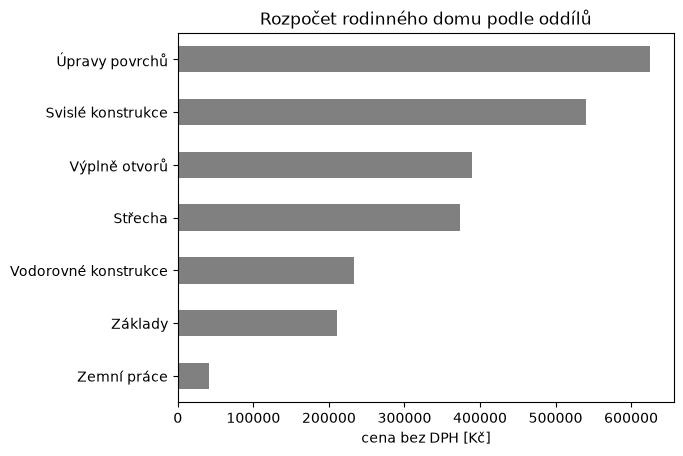

In [23]:
ax = po_oddilech.sort_values().plot(kind="barh", color="gray")
ax.set_xlabel("cena bez DPH [Kč]")
ax.set_ylabel("")
ax.set_title("Rozpočet rodinného domu podle oddílů")
plt.show()

## 8. Čas v tabulce

Data ze senzorů, deník dodávek nebo harmonogram mají sloupec s časem.
Pandas pro něj má vlastní typ `datetime`.

Příklad: senzor zabetonovaný ve stropní desce měří po hodinách teplotu betonu
při tuhnutí. Beton se zahřívá hydratačním teplem a pak chladne. Data si
vyrobíme. Ze souboru by je načetl
`pd.read_csv("soubor.csv", parse_dates=["cas"])`.

In [24]:
cas = pd.date_range("2026-11-02 08:00", periods=96, freq="h")    # 4 dny po hodinach
h = np.arange(96)
teplota = 7 + 3 * np.sin(2 * np.pi * h / 24) + 24 * (h / 20) * np.exp(1 - h / 20)

mereni = pd.DataFrame({"cas": cas, "teplota": teplota.round(1)})
mereni.head()

,cas,teplota
0,2026-11-02 08:00:00,7.0
1,2026-11-02 09:00:00,10.9
2,2026-11-02 10:00:00,14.4
3,2026-11-02 11:00:00,17.5
4,2026-11-02 12:00:00,20.3


Ze sloupce s časem se přes `.dt` dostanete k jeho částem:

In [25]:
print(mereni["cas"].dt.hour.head(3))
print(mereni["cas"].dt.date.head(3))
print(mereni["cas"].dt.day_of_week.head(3))    # 0 = pondeli, 6 = nedele

0     8
1     9
2    10
Name: cas, dtype: int32
0    2026-11-02
1    2026-11-02
2    2026-11-02
Name: cas, dtype: object
0    0
1    0
2    0
Name: cas, dtype: int32


Časy jde porovnávat s textem ve tvaru `"rok-měsíc-den hodina:minuta"`
a odečítat. Rozdíl dvou časů je **doba trvání** (`Timedelta`), na hodiny
ji převede `.dt.total_seconds() / 3600`:

In [26]:
mereni["stari_h"] = (mereni["cas"] - mereni["cas"].iloc[0]).dt.total_seconds() / 3600

i = mereni["teplota"].idxmax()        # popisek radku s maximem, jako argmax
print(mereni.loc[i])

print(mereni[mereni["cas"] >= "2026-11-05 06:00"].head(3))

cas        2026-11-03 12:00:00
teplota                   32.1
stari_h                   28.0
Name: 28, dtype: object


                   cas  teplota  stari_h
70 2026-11-05 06:00:00     12.4     70.0
71 2026-11-05 07:00:00     12.9     71.0
72 2026-11-05 08:00:00     13.4     72.0


Seskupit jde i podle části času. Denní minimum, maximum a průměr:

In [27]:
mereni.groupby(mereni["cas"].dt.date)["teplota"].agg(["min", "max", "mean"]).round(1)

,min,max,mean
cas,,,
2026-11-02,7.0,28.5,23.0
2026-11-03,23.0,32.1,29.0
2026-11-04,13.7,22.2,19.9
2026-11-05,8.5,15.2,12.8
2026-11-06,7.2,8.9,7.8


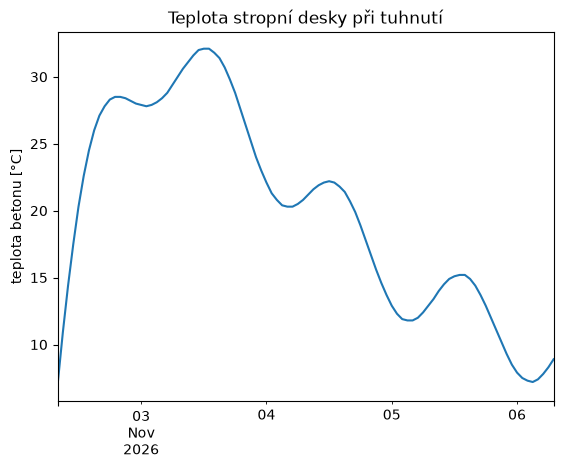

In [28]:
ax = mereni.plot(x="cas", y="teplota", legend=False)
ax.set_xlabel("")
ax.set_ylabel("teplota betonu [°C]")
ax.set_title("Teplota stropní desky při tuhnutí")
plt.show()

## 9. Časté chyby

**Víc sloupců jednými závorkami.** Pandas hledá jeden sloupec se jménem
`("polozka", "mj")`:

In [29]:
rozpocet["polozka", "mj"]

KeyError: ('polozka', 'mj')

Správně dvojími závorkami: `rozpocet[["polozka", "mj"]]`.

**Zřetězené přiřazení.** Dvoje závorky za sebou vyberou nejdřív kopii a do ní
se přiřadí. Původní tabulka se nezmění a pandas vypíše varování:

In [30]:
rozpocet[rozpocet["mj"] == "t"]["jedn_cena"] = 0
print(rozpocet.loc[rozpocet["mj"] == "t", "jedn_cena"])     # porad puvodni ceny

7     32500.0
13    33800.0
Name: jedn_cena, dtype: float64


C:\Users\Tomas\AppData\Local\Temp\ipykernel_43544\3372943801.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#chained-assignment
  rozpocet[rozpocet["mj"] == "t"]["jedn_cena"] = 0


Správně jedním `loc`: `rozpocet.loc[rozpocet["mj"] == "t", "jedn_cena"] = 0`.

**Metoda vrací novou tabulku.** `rozpocet.sort_values("cena")` ani
`rozpocet.dropna()` tabulku nezmění. Výsledek je potřeba uložit:
`serazeny = rozpocet.sort_values("cena")`.

**`and` místo `&`.** Stejně jako v NumPy: `(a > 1) & (b < 2)`, se závorkami.

**Soubor nenalezen.** Cesta se počítá od složky s notebookem:

In [31]:
pd.read_csv("rozpocet.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'rozpocet.csv'

**České CSV z Excelu.** Český Excel ukládá CSV se středníkem jako oddělovačem
a s desetinnou čárkou. Pandas to načte, když mu to řeknete:

```python
pd.read_csv("export.csv", sep=";", decimal=",")
```

Bez toho dostanete jeden dlouhý sloupec, nebo čísla načtená jako text.

**Tichý součet s `NaN`.** `sum()` a `mean()` chybějící hodnoty přeskočí.
Kontrolujte `df.isna().sum()`.

## Shrnutí

| Zápis | Význam |
|---|---|
| `import pandas as pd` | obvyklý import |
| `pd.DataFrame({"a": [...], "b": [...]})` | tabulka ze slovníku seznamů |
| `pd.read_csv("soubor.csv", parse_dates=["cas"])` | tabulka ze souboru CSV |
| `df.head()`, `df.info()`, `df.describe()` | první pohled na tabulku |
| `df["a"]`, `df[["a", "b"]]` | jeden sloupec (`Series`), víc sloupců |
| `df.loc[radky, sloupce]` | výběr podle popisků, výřez včetně konce |
| `df.iloc[radky, sloupce]` | výběr podle pořadí |
| `df[maska]` | řádky, kde maska platí |
| `df.loc[maska, "a"] = hodnota` | změna hodnot maskou |
| `s.isin([...])`, `s.str.contains("...")` | masky pro text |
| `s.unique()`, `s.value_counts()` | výskyt hodnot |
| `df["c"] = df["a"] * df["b"]` | nový sloupec |
| `df.sort_values("a", ascending=False)` | řazení, vrací novou tabulku |
| `df.isna().sum()` | počet chybějících hodnot ve sloupcích |
| `df.fillna(hodnota)`, `df.dropna()` | doplnění, vyhození chybějících |
| `df.groupby("a")["b"].sum()` | součet podle skupin |
| `.agg(["count", "sum", "max"])` | víc agregací najednou |
| `s.idxmax()` | popisek řádku s maximem |
| `s.dt.hour`, `s.dt.date`, `s.dt.day_of_week` | části času |
| `s.dt.total_seconds()` | doba trvání v sekundách |
| `df.plot(x="a", y="b")`, `s.plot(kind="barh")` | graf, vrací osy `ax` |

Co si odnést:

* `DataFrame` je tabulka, `Series` je jeden sloupec, uvnitř je pole NumPy
* novou tabulku si vždycky nejdřív prohlédněte: `head`, `info`, `describe`,
  `isna().sum()`
* filtrování maskou a výpočet bez cyklu fungují jako v NumPy
* `groupby` = rozděl, spočítej, slož
* měnit hodnoty jedním `loc[maska, sloupec]`, nikdy dvojími závorkami za sebou
* chybějící hodnoty se samy neohlásí

V lekci 10 se podíváme na soubory: jak je číst, zapisovat a jak výsledky
z pandas uložit.

## Ukázka: co Python ještě umí

*Tahle část není látka do testu. Nemusíte rozumět každému řádku.*

**IFC** je otevřený formát BIM modelů. Uloží ho Revit, ArchiCAD, Allplan
i další programy. Balíček `ifcopenshell` umí IFC model číst i zapisovat.
Instalace: `uv add ifcopenshell`.

Otevřeme vzorový model rodinného domu AC20-FZK-Haus, který volně zveřejnil
Karlsruhe Institute of Technology. Model je z německého ArchiCADu, proto mají
podlaží německé názvy. Z modelu vytáhneme stěny, desky, okna a dveře a jejich
výměry z něj dáme do tabulky pandas:

In [32]:
import ifcopenshell
import ifcopenshell.util.element as ifc_util

model = ifcopenshell.open("Data/AC20-FZK-Haus.ifc")
print(model.schema, "-", len(model.by_type("IfcElement")), "prvku")

podlazi_cz = {"Erdgeschoss": "přízemí", "Dachgeschoss": "podkroví"}

radky = []
for typ in ["IfcWall", "IfcSlab", "IfcWindow", "IfcDoor"]:
    for prvek in model.by_type(typ):
        vymery = ifc_util.get_psets(prvek).get("BaseQuantities", {})
        radky.append({
            "typ": typ,
            "nazev": prvek.Name,
            "podlazi": podlazi_cz[ifc_util.get_container(prvek).Name],
            "objem": vymery.get("NetVolume"),
            "plocha": vymery.get("NetSideArea", vymery.get("NetArea", vymery.get("Area"))),
        })

prvky = pd.DataFrame(radky)
prvky.head(8)

IFC4 - 102 prvku


,typ,nazev,podlazi,objem,plocha
0,IfcWall,Wand-Int-ERDG-4,přízemí,2.496240,10.42500
1,IfcWall,Wand-Int-ERDG-2,přízemí,2.909316,11.82215
2,IfcWall,Wand-Int-ERDG-1,přízemí,2.226000,9.27500
3,IfcWall,Wand-Int-ERDG-3,přízemí,3.412152,13.91730
4,IfcWall,Wand-Int-ERDG-5,přízemí,2.088962,8.75000
5,IfcWall,Wand-Ext-ERDG-1,přízemí,5.807970,18.75990
6,IfcWall,Wand-Ext-ERDG-4,přízemí,6.604875,22.01625
7,IfcWall,Wand-Ext-ERDG-3,přízemí,6.417000,21.09000


Teď už je to obyčejná tabulka a funguje všechno z dnešní lekce. Výkaz výměr
podle podlaží a typu prvku:

In [33]:
prvky.groupby(["podlazi", "typ"])[["objem", "plocha"]].agg("sum").round(1)

objem  plocha
podlazi  typ                     
podkroví IfcSlab     53.0   265.0
         IfcWall     15.2    50.6
         IfcWindow    0.0     1.6
přízemí  IfcDoor      0.0    12.1
         IfcSlab     24.0   120.0
         IfcWall     39.3   139.8
         IfcWindow    0.0    21.6

Okna a dveře v modelu objem nemají, ve sloupci je `NaN`. Součet je proto 0,
přesně jako u vnitřních dveří v oddílu 6.

Když architekt model změní, stačí notebook spustit znovu a výkaz je aktuální.
Napojení na rozpočet z oddílu 5 je pak jen další `groupby` a násobení cenou.
Tak vypadá automatizace, o které se v digitalizaci stavebnictví mluví.